# Análisis numérico de descargas

Cada sección corresponde a una etapa del análisis (ver la tabla de etapas en `CLAUDE.md`).
Los métodos están en `metodos/` y las etapas, en `analisis/`; acá solo se llaman y se muestran los resultados.
Unidades internas: bytes y segundos. 1 MB = 10⁶ B.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from analisis.preparacion import cargar_corrida, preparar_corrida

corridas = pd.read_csv("datos/corridas.csv")
corridas[["corrida", "banda", "ubicacion", "carga_extra", "tamano_bytes", "senal_dbm", "wget_vel"]]

,corrida,banda,ubicacion,carga_extra,tamano_bytes,senal_dbm,wget_vel
0,C1,5 GHz,cerca del router (4 m),ninguna,2927861760,-54.0,NaN
1,C2,5 GHz,cerca del router (4 m),Netflix en el TV,2927861760,-55.0,10.2 MB/s
2,C3,2.4 GHz,cerca del router (4 m),ninguna,2927861760,-42.0,8.53 MB/s
3,C4,2.4 GHz,"balcón (6 m), puerta cerrada",ninguna,2927861760,NaN,4.30 MB/s


## Etapa 0: preparación

Para cada corrida:
1. `B(t) = C(t) − C(t₀)`, con `C` el contador del sistema.
2. Tasa de fondo `r_f`: pendiente por mínimos cuadrados en los primeros y en los últimos 30 s (cada tramo por separado, se promedian).
3. Bytes de la descarga: `B_d(t) = B(t) − r_f·t`.
4. `v∞`: pendiente de `B_d` entre el 20 % y el 80 % de los bytes.
5. `v = dB_d/dt` con la fórmula de 3 puntos; `t_ini` y `t_fin` son el primer y el último instante con `v > 0,1·v∞`.
6. Sobrecarga de protocolo: `p = (B_d(t_fin) − S) / S`.

In [2]:
resultados = {}
for _, fila in corridas.iterrows():
    t, B = cargar_corrida(f"datos/{fila.corrida.lower()}.csv")
    resultados[fila.corrida] = {"t": t, "B": B, "S": fila.tamano_bytes,
                                **preparar_corrida(t, B, fila.tamano_bytes)}

tabla = pd.DataFrame({
    c: {
        "h medio [s]": r["h"],
        "desvío de h [s]": r["desvio_h"],
        "r_f inicio [B/s]": r["r_inicio"],
        "r_f final [B/s]": r["r_final"],
        "r_f [B/s]": r["r_f"],
        "v∞ [MB/s]": r["v_inf"] / 1e6,
        "t_ini [s]": r["t_ini"],
        "t_fin [s]": r["t_fin"],
        "duración [s]": r["t_fin"] - r["t_ini"],
        "B_d(t_fin) [B]": r["B_d"][r["i_fin"]],
        "p [%]": 100 * r["p"],
    }
    for c, r in resultados.items()
})
tabla.style.format("{:.6g}")

,C1,C2,C3,C4
h medio [s],0.1,0.1,0.1,0.1
desvío de h [s],7.92502e-05,8.20781e-05,0.000110703,7.6824e-05
r_f inicio [B/s],737.467,1021.86,689.983,278.932
r_f final [B/s],1118.65,217.501,1081.78,576.205
r_f [B/s],928.06,619.682,885.882,427.568
v∞ [MB/s],11.5788,11.2702,9.43216,4.67295
t_ini [s],32.6001,35.6001,34.9001,33.7003
t_fin [s],299,309.4,361.5,682.2
duración [s],266.4,273.8,326.6,648.5
B_d(t_fin) [B],3.07638e+09,3.07582e+09,3.07469e+09,3.07473e+09


### Control contra `wget`

`wget` informa la velocidad media de toda la descarga, `S / duración`, en unidades de 2²⁰ B aunque diga "MB/s".
Si la duración medida es correcta, las dos columnas tienen que coincidir. (C1 no tiene el dato.)

In [3]:
pd.DataFrame({
    "S / duración [MiB/s]": {c: r["S"] / (r["t_fin"] - r["t_ini"]) / 2**20 for c, r in resultados.items()},
    "wget": corridas.set_index("corrida")["wget_vel"],
})

,S / duración [MiB/s],wget
C1,10.481331,NaN
C2,10.198044,10.2 MB/s
C3,8.549373,8.53 MB/s
C4,4.305669,4.30 MB/s


### Bytes de la descarga en cada corrida

Las líneas punteadas marcan `t_ini` y `t_fin`. Mismo eje vertical en las cuatro, para comparar.

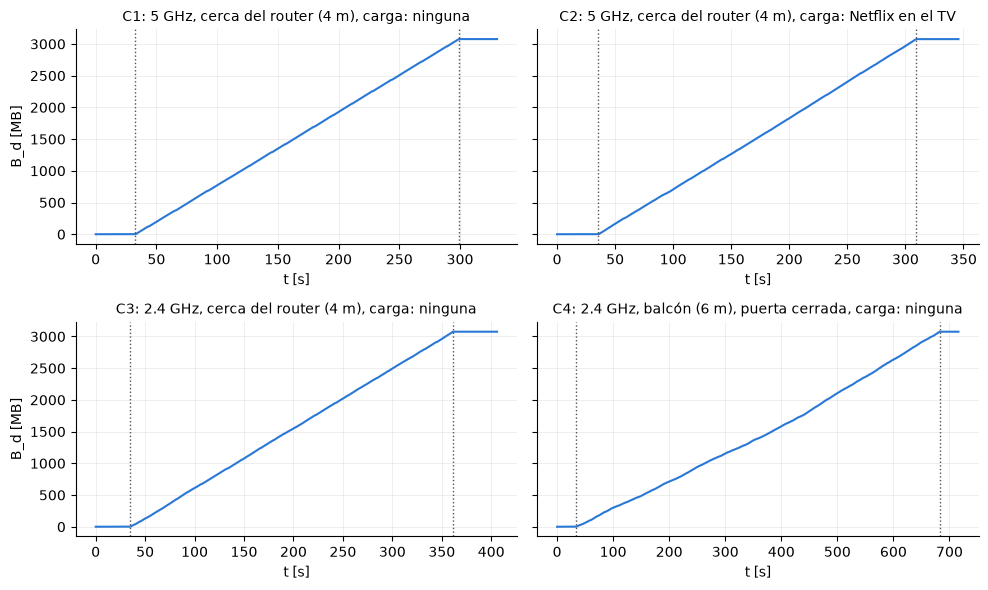

In [4]:
fig, ejes = plt.subplots(2, 2, figsize=(10, 6), sharey=True)
for eje, (c, r) in zip(ejes.flat, resultados.items()):
    eje.plot(r["t"], r["B_d"] / 1e6, color="#2a78d6", linewidth=1.5)
    for t_marca in (r["t_ini"], r["t_fin"]):
        eje.axvline(t_marca, color="#52514e", linewidth=1, linestyle=":")
    fila = corridas.set_index("corrida").loc[c]
    eje.set_title(f"{c}: {fila.banda}, {fila.ubicacion}, carga: {fila.carga_extra}", fontsize=10)
    eje.set_xlabel("t [s]")
    eje.grid(alpha=0.3, linewidth=0.5)
    eje.spines[["top", "right"]].set_visible(False)
for eje in ejes[:, 0]:
    eje.set_ylabel("B_d [MB]")
fig.tight_layout()